# 07 – Gradient Boosting, MLP và so sánh các họ mô hình

Tiếp nối notebook 05 (Random Forest). Cùng bộ đặc trưng `full` (cảm biến + thời tiết + `lights` + thời gian + `rv1`),
cùng cách chia train/validation theo thời gian và cùng CV `TimeSeriesSplit(5)` trên tập train.

1. **Histogram Gradient Boosting** – tinh chỉnh siêu tham số bằng CV theo thời gian.
2. **MLP** (mạng nơ-ron truyền thẳng) – vài cấu hình nhỏ, có điều chuẩn L2.
3. **So sánh các họ mô hình** trên validation → trả lời **RQ2**: mô hình phi tuyến có vượt trội mô hình tuyến tính không?

> Nguyên tắc chọn siêu tham số: chọn theo **`cv_RMSE`** (CV trên train), **không** chọn theo validation, để validation
> vẫn là thước đo khách quan khi so sánh các họ mô hình. Tập test chưa dùng – chỉ dùng một lần ở notebook 09.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso
from sklearn.neural_network import MLPRegressor

from src.config import RANDOM_STATE, TABLES_DIR
from src.data_loader import load_raw_data
from src.evaluate import HourMeanBaseline
from src.features import make_xy
from src.preprocessing import make_pipeline
from src.split import time_split
from src.train import cv_evaluate, fit_and_validate
from src.visualization import save_fig, set_style

warnings.filterwarnings("ignore", category=ConvergenceWarning)
set_style()
pd.set_option("display.width", 160)
train, val, test = time_split(load_raw_data())
X_tr, y_tr = make_xy(train)
X_va, y_va = make_xy(val)
cols = list(X_tr.columns)
SHOW = ["train_RMSE", "cv_RMSE", "cv_RMSE_std", "cv_R2", "val_RMSE", "val_MAE", "val_R2"]
print("Train:", X_tr.shape, "| Validation:", X_va.shape)

Train: (13814, 31) | Validation: (2960, 31)


## 1. Histogram Gradient Boosting

`HistGradientBoostingRegressor` của scikit-learn: cùng thuật toán với LightGBM (gom giá trị đặc trưng vào 255 "thùng"
rồi tìm ngưỡng tách trên histogram), chạy nhanh và không cần cài thêm thư viện.

Gradient Boosting xây cây **tuần tự**, mỗi cây sửa phần sai số còn lại của các cây trước. Các tham số kiểm soát
overfitting:
- `learning_rate`: mỗi cây đóng góp bao nhiêu – nhỏ hơn thì học chậm và chắc hơn.
- `max_leaf_nodes`: số lá tối đa mỗi cây (độ phức tạp từng cây).
- `min_samples_leaf`: số mẫu tối thiểu mỗi lá – như ở Random Forest, đây là "phanh" quan trọng nhất.
- `l2_regularization = 1`, `max_iter = 300` cố định; tắt `early_stopping` vì cơ chế này tách validation **ngẫu nhiên**
  (sai với dữ liệu chuỗi thời gian).

### 1.1 Mặc định của thư viện – mốc so sánh

In [2]:
gb_results = {}
hgb_default = make_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE), cols, kind="tree")
_, r = fit_and_validate(hgb_default, X_tr, y_tr, X_va, y_va)
r.update(cv_evaluate(hgb_default, X_tr, y_tr))
gb_results["HGB mặc định"] = r
pd.DataFrame(gb_results).T[SHOW].round(3)

,train_RMSE,cv_RMSE,cv_RMSE_std,cv_R2,val_RMSE,val_MAE,val_R2
HGB mặc định,46.142,105.595,8.703,-0.072,86.73,46.936,0.116


### 1.2 Tìm siêu tham số (18 cấu hình × 5 fold)

In [3]:
grid = [dict(learning_rate=lr, max_leaf_nodes=leaves, min_samples_leaf=msl)
        for lr in (0.02, 0.05, 0.1) for leaves in (7, 15, 31) for msl in (50, 100)]


def hgb(**kw):
    return make_pipeline(HistGradientBoostingRegressor(max_iter=300, l2_regularization=1.0, early_stopping=False,
                                                       random_state=RANDOM_STATE, **kw), cols, kind="tree")


rows = []
for params in grid:
    r = cv_evaluate(hgb(**params), X_tr, y_tr)
    rows.append(params | {k: r[k] for k in ("train_RMSE", "cv_RMSE", "cv_RMSE_std", "cv_R2")})
search = pd.DataFrame(rows).sort_values("cv_RMSE").reset_index(drop=True)
search.round(3).head(8)

,learning_rate,max_leaf_nodes,min_samples_leaf,train_RMSE,cv_RMSE,cv_RMSE_std,cv_R2
0,0.02,7,100,84.266,94.510,4.581,0.144
1,0.02,15,100,76.024,95.352,5.259,0.128
2,0.02,7,50,82.485,96.089,6.177,0.115
3,0.05,7,100,75.893,96.298,4.005,0.109
4,0.02,31,100,70.426,96.370,4.987,0.109
5,0.05,15,100,64.443,97.745,4.629,0.082
6,0.05,7,50,73.051,98.216,4.778,0.067
7,0.02,15,50,71.868,98.478,8.078,0.066


Đã lưu hình: reports/figures/07_hgb_tuning.png


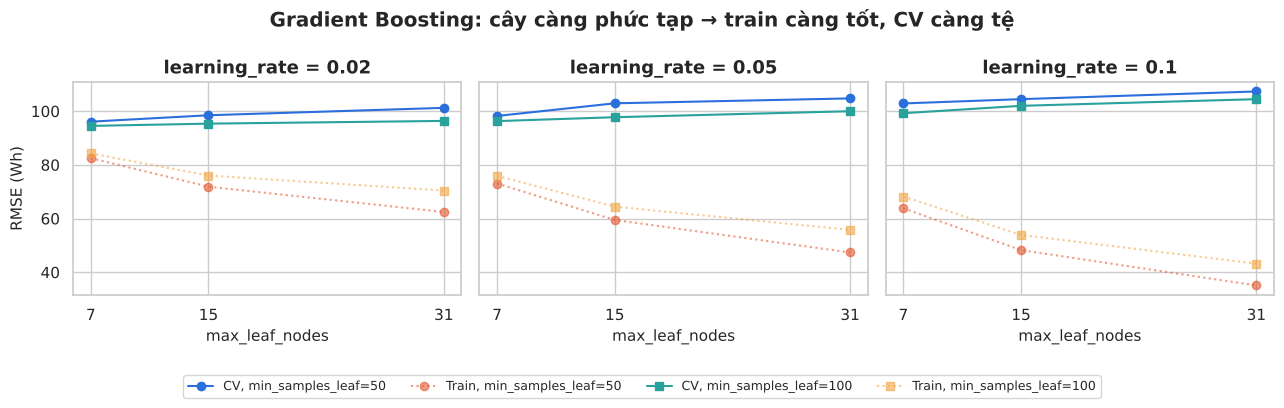

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, lr in zip(axes, (0.02, 0.05, 0.1)):
    sub = search[search["learning_rate"] == lr]
    for msl, marker in ((50, "o"), (100, "s")):
        s = sub[sub["min_samples_leaf"] == msl].sort_values("max_leaf_nodes")
        ax.plot(s["max_leaf_nodes"], s["cv_RMSE"], marker=marker, label=f"CV, min_samples_leaf={msl}")
        ax.plot(s["max_leaf_nodes"], s["train_RMSE"], marker=marker, linestyle=":", alpha=0.6,
                label=f"Train, min_samples_leaf={msl}")
    ax.set_title(f"learning_rate = {lr}")
    ax.set_xlabel("max_leaf_nodes")
    ax.set_xticks([7, 15, 31])
axes[0].set_ylabel("RMSE (Wh)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Gradient Boosting: cây càng phức tạp → train càng tốt, CV càng tệ", fontweight="bold")
fig.tight_layout(rect=(0, 0.05, 1, 1))
save_fig(fig, "07_hgb_tuning")
plt.show()

In [5]:
best_hgb_params = search.iloc[0][["learning_rate", "max_leaf_nodes", "min_samples_leaf"]].to_dict()
best_hgb_params = {"learning_rate": float(best_hgb_params["learning_rate"]),
                   "max_leaf_nodes": int(best_hgb_params["max_leaf_nodes"]),
                   "min_samples_leaf": int(best_hgb_params["min_samples_leaf"])}
print("Cấu hình tốt nhất theo cv_RMSE:", best_hgb_params)
_, r = fit_and_validate(hgb(**best_hgb_params), X_tr, y_tr, X_va, y_va)
r.update(cv_evaluate(hgb(**best_hgb_params), X_tr, y_tr))
gb_results["HGB tinh chỉnh"] = r
pd.DataFrame(gb_results).T[SHOW].round(3)

Cấu hình tốt nhất theo cv_RMSE: {'learning_rate': 0.02, 'max_leaf_nodes': 7, 'min_samples_leaf': 100}


,train_RMSE,cv_RMSE,cv_RMSE_std,cv_R2,val_RMSE,val_MAE,val_R2
HGB mặc định,46.142,105.595,8.703,-0.072,86.730,46.936,0.116
HGB tinh chỉnh,84.266,94.510,4.581,0.144,84.379,44.939,0.163


**Nhận xét:**
- Tham số mặc định (`max_leaf_nodes=31`, `min_samples_leaf=20`, `learning_rate=0.1`) **overfit** giống Random Forest mặc định: RMSE train ≈ 46 Wh nhưng CV ≈ 106 Wh, còn kém hơn baseline theo giờ.
- Hình cho thấy rõ quy luật: tăng `max_leaf_nodes` hoặc `learning_rate` làm RMSE **train giảm** nhưng RMSE **CV tăng**. Cấu hình tốt nhất là cấu hình **đơn giản nhất** trong lưới: `learning_rate=0.02`, `max_leaf_nodes=7`, `min_samples_leaf=100`.
- Sau tinh chỉnh: CV RMSE 105,6 → 94,5 Wh, validation RMSE 86,7 → **84,4 Wh** (R² 0,16). Khoảng cách train–CV thu hẹp từ ~59 Wh còn ~10 Wh.
- Dữ liệu chỉ cho phép mô hình **rất đơn giản**: phần lớn biến động của `Appliances` (các đỉnh do con người bật thiết bị) không giải thích được bằng nhiệt độ/độ ẩm/thời tiết.

## 2. MLP – mạng nơ-ron truyền thẳng

- Đầu vào chuẩn hóa bằng `StandardScaler` + one-hot `day_of_week` (pipeline `kind="linear"`, giống Ridge/Lasso) –
  MLP rất nhạy với thang đo.
- Tối ưu bằng Adam, tối đa 200 vòng; `alpha` là hệ số phạt L2 trên trọng số.
- Tắt `early_stopping` vì cơ chế này lấy validation **ngẫu nhiên** – trái nguyên tắc chuỗi thời gian.

In [6]:
mlp_configs = {
    "MLP (16)": dict(hidden_layer_sizes=(16,), alpha=10.0),
    "MLP (32)": dict(hidden_layer_sizes=(32,), alpha=10.0),
    "MLP (32), alpha=100": dict(hidden_layer_sizes=(32,), alpha=100.0),
    "MLP (64, 32)": dict(hidden_layer_sizes=(64, 32), alpha=10.0),
}
mlp_results, mlp_models = {}, {}
for name, kw in mlp_configs.items():
    pipe = make_pipeline(MLPRegressor(max_iter=200, random_state=RANDOM_STATE, **kw), cols, kind="linear")
    mlp_models[name] = pipe
    _, r = fit_and_validate(pipe, X_tr, y_tr, X_va, y_va)
    r.update(cv_evaluate(pipe, X_tr, y_tr))
    mlp_results[name] = r
mlp_table = pd.DataFrame(mlp_results).T[SHOW].round(3).sort_values("cv_RMSE")
mlp_table

,train_RMSE,cv_RMSE,cv_RMSE_std,cv_R2,val_RMSE,val_MAE,val_R2
MLP (16),94.715,96.962,2.973,0.095,89.358,49.914,0.061
"MLP (32), alpha=100",93.480,97.212,3.188,0.091,87.822,48.775,0.093
MLP (32),92.434,98.892,2.384,0.057,90.196,52.852,0.044
"MLP (64, 32)",77.790,116.890,17.940,-0.339,110.775,65.618,-0.442


**Nhận xét:**
- MLP **không vượt** được các mô hình khác. Mạng lớn nhất `(64, 32)` overfit nặng (RMSE train ≈ 78 Wh nhưng CV ≈ 117 Wh, R² validation âm).
- Mạng nhỏ một lớp ẩn 16 nơ-ron, phạt L2 mạnh (`alpha=10`) ổn định nhất (độ lệch chuẩn CV thấp nhất, ≈ 3 Wh) nhưng validation RMSE ≈ 89 Wh – kém cả baseline theo giờ.
- Lý do: chỉ ~14 nghìn mẫu, tín hiệu yếu, nhiều nhiễu → MLP có quá nhiều tham số so với lượng thông tin thật sự có trong dữ liệu. Đây là trường hợp kinh điển mà mô hình cây/tuyến tính có điều chuẩn phù hợp hơn mạng nơ-ron.

## 3. So sánh các họ mô hình (RQ2)

Mỗi họ lấy đại diện tốt nhất đã tìm được:
- Baseline theo giờ (notebook 04) – mốc "không cần học máy".
- Lasso `alpha=1` – tuyến tính tốt nhất (notebook 04).
- Random Forest `min_samples_leaf=50, max_features=0.33` (notebook 05).
- HGB tinh chỉnh và MLP tốt nhất theo `cv_RMSE` (notebook này).

In [7]:
best_mlp_name = mlp_table.index[0]
candidates = {
    "Baseline theo giờ": HourMeanBaseline(),
    "Lasso (alpha=1)": make_pipeline(Lasso(alpha=1.0, max_iter=10000), cols, kind="linear"),
    "Random Forest (leaf=50)": make_pipeline(
        RandomForestRegressor(n_estimators=100, min_samples_leaf=50, max_features=0.33,
                              random_state=RANDOM_STATE, n_jobs=-1), cols, kind="tree"),
    "HGB tinh chỉnh": hgb(**best_hgb_params),
    best_mlp_name: mlp_models[best_mlp_name],
}
family_results = {}
for name, model in candidates.items():
    _, r = fit_and_validate(model, X_tr, y_tr, X_va, y_va)
    r.update(cv_evaluate(model, X_tr, y_tr))
    family_results[name] = r
family = pd.DataFrame(family_results).T[SHOW + ["fit_time_s"]].round(3).sort_values("val_RMSE")
family

,train_RMSE,cv_RMSE,cv_RMSE_std,cv_R2,val_RMSE,val_MAE,val_R2,fit_time_s
HGB tinh chỉnh,84.266,94.510,4.581,0.144,84.379,44.939,0.163,0.313
Random Forest (leaf=50),86.883,94.031,4.706,0.153,84.680,46.652,0.157,0.865
Lasso (alpha=1),99.200,96.115,4.960,0.116,85.263,49.125,0.146,0.024
Baseline theo giờ,104.705,95.252,8.217,0.135,87.230,48.546,0.106,0.002
MLP (16),94.715,96.962,2.973,0.095,89.358,49.914,0.061,1.385


Đã lưu hình: reports/figures/07_model_comparison.png


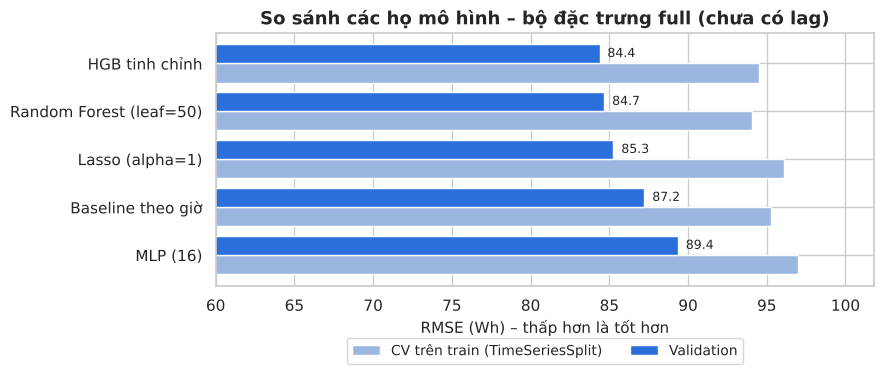

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
order = family.sort_values("val_RMSE", ascending=False)
y = np.arange(len(order))
ax.barh(y - 0.2, order["cv_RMSE"], height=0.4, label="CV trên train (TimeSeriesSplit)", color="#9bb7e0")
ax.barh(y + 0.2, order["val_RMSE"], height=0.4, label="Validation", color="#2a6fdb")
for i, v in enumerate(order["val_RMSE"]):
    ax.text(v + 0.5, i + 0.2, f"{v:.1f}", va="center", fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(order.index)
ax.set_xlabel("RMSE (Wh) – thấp hơn là tốt hơn")
ax.set_xlim(left=60)
ax.set_title("So sánh các họ mô hình – bộ đặc trưng full (chưa có lag)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
fig.tight_layout()
save_fig(fig, "07_model_comparison")
plt.show()

In [9]:
TABLES_DIR.mkdir(parents=True, exist_ok=True)
family.to_csv(TABLES_DIR / "07_model_comparison.csv")
import json

(TABLES_DIR / "07_best_hgb_params.json").write_text(json.dumps(best_hgb_params, indent=2))
print("Đã lưu bảng so sánh và siêu tham số HGB tốt nhất vào reports/tables/")

Đã lưu bảng so sánh và siêu tham số HGB tốt nhất vào reports/tables/


### Kết luận RQ2 – Phi tuyến có vượt trội tuyến tính không?

**Không đáng kể** với bộ đặc trưng hiện tại (chưa có thông tin quá khứ):

| | Validation RMSE | So với baseline theo giờ |
|---|---|---|
| Baseline theo giờ | 87,2 Wh | – |
| Lasso | 85,3 Wh | −2,2% |
| Random Forest (điều chuẩn) | 84,7 Wh | −2,9% |
| **HGB tinh chỉnh** | **84,4 Wh** | **−3,3%** |
| MLP (16) | 89,4 Wh | +2,4% |

- HGB và Random Forest tốt nhất nhưng chỉ hơn Lasso ~1 Wh – nhỏ hơn nhiều so với độ lệch chuẩn giữa các fold CV (~4,5 Wh), nên **không thể kết luận là hơn thật**.
- Mọi mô hình chỉ hơn baseline theo giờ khoảng 2–3 Wh: cảm biến nhiệt độ/độ ẩm và thời tiết **chỉ thêm rất ít thông tin** so với "biết giờ trong ngày". R² validation tốt nhất ≈ 0,16.
- Mô hình phi tuyến **chỉ có lợi khi được điều chuẩn mạnh**; để mặc định chúng còn tệ hơn mô hình tuyến tính.
- Bài báo gốc đạt R² test ≈ 0,57 với GBM, cao hơn nhiều so với ≈ 0,16 ở đây. Nhóm chia train/val/test **theo thời gian** (test là 3 tuần cuối, mùa khác với train). **Cần đối chiếu lại cách bài báo chọn tập test** khi viết báo cáo: nếu tập test được lấy ngẫu nhiên xen kẽ trong cả giai đoạn, các mẫu cách nhau 10 phút nằm ở cả train và test nên điểm sẽ cao hơn nhiều so với cách chia của nhóm.

→ Notebook 08 kiểm tra RQ4: thêm tiêu thụ 10–60 phút trước có thay đổi bức tranh này không.